# Object-Oriented Data Processing and Analysis Pipeline 
### Done by Ani Hovhannisyan

**Dataset:** Global Cancer Patients 2015–2024  
**Source:** https://www.kaggle.com/datasets/zahidmughal2343/global-cancer-patients-2015-2024

---

## Overview

This notebook implements a data processing and analysis pipeline using object-oriented programming (OOP) in Python. The pipeline consists of three classes:

- **`DataLoader`** – loads the CSV dataset, cleans it, and prepares it for analysis
- **`DataAnalyzer`** – performs descriptive statistics, grouping, and trend analysis using Pandas and NumPy
- **`Visualizer`** – generates 8 informative plots using Matplotlib

The dataset contains 50,000 patient records from 10 countries (2015–2024) with demographics, cancer type/stage, 5 risk factors, treatment cost, survival years, and severity score.

## 1. Imports

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Class Definitions

### 2.1 `DataLoader`

Responsible for loading the dataset and performing cleaning steps:
1. Drop duplicate rows
2. Handle missing values (fill numeric columns with median, text with mode)
3. Fix data types (Age/Year → int, numeric measurements → float)
4. Standardize text (strip whitespace, title-case)

In [51]:
class DataLoader:
    """
    Loads the Global Cancer Patients dataset from a CSV file,
    cleans it, and stores the result as a Pandas DataFrame.
    """

    def __init__(self, filepath):
        # Store the path to the CSV file
        self.filepath = filepath
        # This will hold the cleaned DataFrame after load() is called
        self.df = None

    def load(self):
        """Read the CSV file into a DataFrame and run all cleaning steps."""
        # Load raw CSV into DataFrame
        self.df = pd.read_csv(self.filepath)
        # Remove duplicate rows
        self._drop_duplicates()
        # Fill missing values
        self._handle_missing()
        # Correct data types
        self._fix_types()
        # Clean string columns
        self._clean_text()
        print(f"Dataset loaded: {self.df.shape[0]} rows, {self.df.shape[1]} columns")
        # Return cleaned DataFrame
        return self.df

    def _drop_duplicates(self):
        """Remove completely duplicate rows."""
        # Count rows before removal
        before = len(self.df)
        # Drop identical rows
        self.df = self.df.drop_duplicates()
        # Calculate how many were removed
        removed = before - len(self.df)
        print(f"  Dropped {removed} duplicate rows")

    def _handle_missing(self):
        """Handle missing values - fill numeric with median, text with mode."""
        # Total missing values before filling
        missing_before = self.df.isnull().sum().sum()

        # Fill numeric columns with median if they have missing values
        # Select only numeric columns
        numeric_cols = self.df.select_dtypes(include=[np.number]).columns
        # Loop through each numeric column
        for col in numeric_cols:
            # Check if column has any missing values
            if self.df[col].isnull().sum() > 0:
                # Calculate the median value
                median_value = self.df[col].median()
                # Fill missing values with the median
                self.df[col] = self.df[col].fillna(median_value)

        # Fill text columns with mode if they have missing values
        # Select only text/object columns
        text_cols = self.df.select_dtypes(include=['object']).columns
        # Loop through each text column
        for col in text_cols:
            # Check if column has any missing values
            if self.df[col].isnull().sum() > 0:
                # Get the most frequent value (mode)
                mode_value = self.df[col].mode()[0]
                # Fill missing values with the mode
                self.df[col] = self.df[col].fillna(mode_value)

        # Total missing values after filling
        missing_after = self.df.isnull().sum().sum()
        print(f"  Handled {missing_before - missing_after} missing values")

    def _fix_types(self):
        """Convert columns to the correct data types."""
        # Check if Age column exists
        if 'Age' in self.df.columns:
            # Convert Age to integer type
            self.df['Age'] = self.df['Age'].astype(int)
        # Check if Year column exists
        if 'Year' in self.df.columns:
            # Convert Year to integer type
            self.df['Year'] = self.df['Year'].astype(int)
        # Check if Survival_Years column exists
        if 'Survival_Years' in self.df.columns:
            # Convert Survival_Years to float type
            self.df['Survival_Years'] = self.df['Survival_Years'].astype(float)
        # Check if Treatment_Cost_USD column exists
        if 'Treatment_Cost_USD' in self.df.columns:
            # Convert Treatment_Cost_USD to float type
            self.df['Treatment_Cost_USD'] = self.df['Treatment_Cost_USD'].astype(float)

    def _clean_text(self):
        """Strip whitespace and standardize capitalization in string columns."""
        # Select only text/string columns (data type 'object')
        text_columns = self.df.select_dtypes(include=['object']).columns
        # Loop through each text column
        for col in text_columns:
            # Convert to string and remove leading/trailing whitespace
            self.df[col] = self.df[col].astype(str).str.strip()
            
            # Skip Cancer_Stage because it contains Roman numerals (II, III, IV)
            # .str.title() would corrupt them into 'Ii', 'Iii', 'Iv'
            if col != 'Cancer_Stage':
                # Capitalize first letter of each word for all other text columns
                self.df[col] = self.df[col].str.title()
            
            # Convert the string 'nan' (created by astype(str)) back to proper NaN
            self.df[col] = self.df[col].replace('Nan', np.nan)

    def get_data(self):
        """Return the cleaned DataFrame."""
        return self.df

    def summary(self):
        """Print a basic summary of the cleaned dataset."""
        print("\n--- Dataset Summary ---")
        # Print number of rows and columns
        print(f"Shape: {self.df.shape}")
        # Print list of all column names
        print(f"\nColumns: {list(self.df.columns)}")
        # Print data type of each column
        print(f"\nData types:\n{self.df.dtypes}")
        # Print count of missing values per column
        print("\nMissing values per column:")
        print(self.df.isnull().sum())
        # Print first 5 rows as preview
        print("\nFirst 5 rows:")
        print(self.df.head())

### 2.2 `DataAnalyzer`

Performs statistical analysis using Pandas grouping and NumPy correlations. Computes descriptive stats, survival trends, risk factor analysis, and severity patterns.

In [52]:
class DataAnalyzer:
    """
    Performs statistical analysis and feature extraction
    on the cleaned cancer patient dataset.
    """

    def __init__(self, df):
        # Store a copy so the original DataFrame is not modified
        self.df = df.copy()

    def descriptive_stats(self):
        """Return descriptive statistics for all numeric columns."""
        print("\n--- Descriptive Statistics ---")
        stats = self.df.describe()
        print(stats)
        return stats

    def survival_by_cancer_type(self):
        """Compute mean survival years grouped by cancer type."""
        # Groups by cancer type and calculates average survival
        result = self.df.groupby("Cancer_Type")["Survival_Years"].mean()
        # Sorts from highest to lowest survival
        result = result.sort_values(ascending=False)
        print("\n--- Mean Survival Years by Cancer Type ---")
        print(result)
        return result

    def survival_by_stage(self):
        """Compute mean survival years grouped by cancer stage."""
        # Groups by cancer stage and calculates average survival
        result = self.df.groupby("Cancer_Stage")["Survival_Years"].mean()
        # Sorts from highest to lowest survival
        result = result.sort_values(ascending=False)
        print("\n--- Mean Survival Years by Cancer Stage ---")
        print(result)
        return result

    def cases_per_year(self):
        """Count the total number of patient records per year."""
        # Groups by year and counts number of rows in each group
        result = self.df.groupby("Year").size()
        # Names the resulting Series for clarity
        result.name = "Case_Count"
        print("\n--- Cases per Year ---")
        print(result)
        return result

    def gender_distribution(self):
        """Count how many patients of each gender are in the dataset."""
        # Counts occurrences of each unique gender value
        result = self.df["Gender"].value_counts()
        print("\n--- Gender Distribution ---")
        print(result)
        return result

    def top_countries_by_cases(self, n=10):
        """Return the top n countries by number of patient records."""
        # Counts patients per country and returns top n
        result = self.df["Country_Region"].value_counts().head(n)
        print(f"\n--- Top {n} Countries/Regions by Number of Cases ---")
        print(result)
        return result

    def age_group_analysis(self):
        """Bin patients into age groups and compute mean survival for each group."""
        # Define bin edges (age boundaries)
        bins = [0, 20, 40, 60, 80, 100]
        # Define labels for each age group
        labels = ["0-20", "21-40", "41-60", "61-80", "81-100"]
        # pd.cut() assigns each age to a group in one line
        self.df["Age_Group"] = pd.cut(self.df["Age"], bins=bins, labels=labels, right=False)
        # Calculate mean survival for each age group
        result = self.df.groupby("Age_Group")["Survival_Years"].mean()
        print("\n--- Mean Survival Years by Age Group ---")
        print(result)
        return result

    def cost_vs_survival_correlation(self):
        """Compute Pearson correlation between treatment cost and survival years."""
        # Extract treatment cost column as numpy array
        cost = self.df["Treatment_Cost_USD"].values
        # Extract survival years column as numpy array
        survival = self.df["Survival_Years"].values
        # Calculate Pearson correlation coefficient using numpy
        corr = np.corrcoef(cost, survival)[0, 1]
        print(f"\n--- Correlation: Treatment Cost vs Survival Years ---")
        print(f"Pearson r = {corr:.4f}")
        return corr

    def survival_trend_by_year(self):
        """Compute mean survival years per year."""
        # Groups by year and calculates average survival
        result = self.df.groupby("Year")["Survival_Years"].mean()
        print("\n--- Mean Survival Years per Year ---")
        print(result)
        return result

    def risk_factor_analysis(self):
        """Analyze correlation between risk factors and survival."""
        # List of risk factor columns to analyze
        risk_factors = ['Genetic_Risk', 'Air_Pollution', 'Alcohol_Use', 'Smoking', 'Obesity_Level']
        # Dictionary to store correlation results
        correlations = {}
        print("\n--- Risk Factors Correlation with Survival ---")
        # Loop through each risk factor
        for factor in risk_factors:
            # Check if the column exists in the DataFrame
            if factor in self.df.columns:
                # Calculate correlation between this risk factor and survival
                corr = np.corrcoef(self.df[factor], self.df['Survival_Years'])[0,1]
                # Store the correlation value in dictionary
                correlations[factor] = corr
                # Print the correlation value
                print(f"{factor}: {corr:.4f}")
        return correlations

    def genetic_risk_vs_severity_corr(self):
        """Compute correlation between Genetic_Risk and Target_Severity_Score."""
        # Extract genetic risk column as numpy array
        gen_risk = self.df["Genetic_Risk"].values
        # Extract severity score column as numpy array
        severity = self.df["Target_Severity_Score"].values
        # Calculate Pearson correlation coefficient using numpy
        corr = np.corrcoef(gen_risk, severity)[0, 1]
        print(f"\n--- Correlation: Genetic Risk vs Severity Score ---")
        print(f"Pearson r = {corr:.4f}")
        return corr

    def get_data(self):
        """Return the current DataFrame."""
        return self.df

### 2.3 `Visualizer`

Generates 8 informative plots showing survival patterns, geographic distribution, and the strongest risk factor predictor (Genetic Risk).

In [53]:
class Visualizer:
    """Simple, informative plots with clear values."""

    def __init__(self, df):
        self.df = df

    def plot_age_distribution(self):
        """Histogram showing the age spread of cancer patients."""
        plt.figure(figsize=(10, 6))
        # Create histogram and capture the bin counts and edges
        counts, bins, _ = plt.hist(self.df['Age'], bins=20, color='steelblue', edgecolor='black')
    
        plt.xlabel('Age')
        plt.ylabel('Number of Patients')
        plt.title('Age Distribution of Cancer Patients')
        plt.grid(True, alpha=0.3)
    
        # Add value labels above each bin
        for i, count in enumerate(counts):
            if count > 0:  # Only label bins that have at least one patient
                # Calculate x position for the label (center of the bin)
                x_pos = (bins[i] + bins[i + 1]) / 2
                # Add text above the bar
                plt.text(x_pos, count + 1, f'{int(count)}', 
                        ha='center', va='bottom', fontsize=8)
    
        plt.tight_layout()
        plt.show()

    def plot_survival_by_cancer_type(self, survival_by_type):
        """Bar chart of mean survival years for each cancer type."""
        # Sort from highest to lowest survival
        sorted_data = survival_by_type.sort_values(ascending=False)
    
        plt.figure(figsize=(12, 6))
        plt.bar(range(len(sorted_data)), sorted_data.values,
                color='maroon', edgecolor='black')
        plt.xticks(range(len(sorted_data)), sorted_data.index,
                rotation=45, ha='right')
        plt.xlabel('Cancer Type')
        plt.ylabel('Mean Survival Years')
        plt.title('Mean Survival Years by Cancer Type')
        plt.grid(True, alpha=0.3, axis='y')
    
        # Add value labels (like age distribution)
        for i, value in enumerate(sorted_data.values):
            plt.text(i, value + 0.05, f'{value:.2f}', 
                    ha='center', va='bottom')
    
        plt.tight_layout()
        plt.show()

    def plot_survival_by_stage(self, survival_by_stage):
        """Bar chart ordered Stage 0 → IV (clinical order, not sorted by value)."""
        # Define correct clinical order
        stage_order = ['Stage 0', 'Stage I', 'Stage II', 'Stage III', 'Stage IV']
        # Keep only stages that exist in the data
        valid_stages = [s for s in stage_order if s in survival_by_stage.index]
        sorted_data = survival_by_stage.reindex(valid_stages)
        
        plt.figure(figsize=(8, 6))
        bars = plt.bar(range(len(sorted_data)), sorted_data.values,
                       color='mediumseagreen', edgecolor='black')
        plt.xticks(range(len(sorted_data)), sorted_data.index)
        plt.ylabel('Mean Survival Years')
        plt.title('Mean Survival Years by Cancer Stage')
        
        # Add value labels
        for bar, value in zip(bars, sorted_data.values):
            plt.text(bar.get_x() + bar.get_width() / 2,
                     bar.get_height() + 0.03,
                     f'{value:.2f}', ha='center', va='bottom')
        
        plt.grid(True, alpha=0.3, axis='y')
        plt.tight_layout()
        plt.show()

    def plot_cases_per_year(self, cases_per_year):
        """Line plot showing how case counts changed over time."""
        plt.figure(figsize=(10, 6))
        plt.plot(cases_per_year.index, cases_per_year.values,
                 marker='o', linewidth=2, color='purple')
        plt.xlabel('Year')
        plt.ylabel('Number of Cases')
        plt.title('Cancer Cases Per Year')
        plt.xticks(cases_per_year.index)
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

    def plot_top_countries(self, top_countries):
        """Bar chart of top 10 countries by number of cases."""
        plt.figure(figsize=(12, 6))
        top_countries.plot(kind='bar', color='slateblue', edgecolor='black')
        plt.xlabel('Country')
        plt.ylabel('Number of Cases')
        plt.title('Top 10 Countries by Number of Cases')
        plt.xticks(rotation=45, ha='right')
        plt.grid(True, alpha=0.3, axis='y')
        
        # Add value labels on top of each bar
        for i, (country, value) in enumerate(top_countries.items()):
            plt.text(i, value + 5, f'{value}', ha='center', va='bottom', fontsize=9)
        
        plt.tight_layout()
        plt.show()

    def plot_cost_vs_survival(self):
        """Heatmap showing density of patients across cost and survival."""
        x = self.df['Treatment_Cost_USD']
        y = self.df['Survival_Years']
        
        # Create 2D grid to show density (hotspots where many points cluster)
        x_bins = np.linspace(x.min(), x.max(), 50)
        y_bins = np.linspace(y.min(), y.max(), 50)
        heatmap, xedges, yedges = np.histogram2d(x, y, bins=[x_bins, y_bins])
        
        plt.figure(figsize=(10, 6))
        extent = [xedges[0], xedges[-1], yedges[0], yedges[-1]]
        plt.imshow(heatmap.T, extent=extent, origin='lower',
                   cmap='hot', aspect='auto')
        plt.colorbar(label='Density')
        plt.xlabel('Treatment Cost (USD)')
        plt.ylabel('Survival Years')
        plt.title('Density Heatmap of Treatment Cost vs Survival Years')
        plt.tight_layout()
        plt.show()

    def plot_gender_distribution(self, gender_dist):
        """Pie chart showing proportion of male, female, and other patients."""

        colors = ['royalblue', 'orangered', 'slategray']

        plt.figure(figsize=(6, 6))
        plt.pie(gender_dist.values, labels=gender_dist.index,
                autopct='%1.1f%%', startangle=90, colors=colors)
        plt.title('Gender Distribution of Patients')
        plt.tight_layout()
        plt.show()

    def plot_genetic_risk_vs_severity(self):
        """Scatter plot with trend line showing relationship between genetic risk and severity."""
        plt.figure(figsize=(10, 6))
        plt.scatter(self.df['Genetic_Risk'], self.df['Target_Severity_Score'],
                    alpha=0.3, s=15, color='darkorange')
        
        # Add trend line (linear fit)
        z = np.polyfit(self.df['Genetic_Risk'], self.df['Target_Severity_Score'], 1)
        p = np.poly1d(z)
        x_trend = np.linspace(self.df['Genetic_Risk'].min(),
                               self.df['Genetic_Risk'].max(), 100)
        plt.plot(x_trend, p(x_trend), 'r-', linewidth=2.5, label='Trend line')
        
        plt.xlabel('Genetic Risk Score (0-10)')
        plt.ylabel('Target Severity Score')
        plt.title('Genetic Risk vs Target Severity Score (with Trend Line)')
        plt.grid(True, alpha=0.3)
        plt.legend()
        
        # Display correlation value on the plot
        corr = np.corrcoef(self.df['Genetic_Risk'],
                           self.df['Target_Severity_Score'])[0, 1]
        plt.text(0.05, 0.95, f'r = {corr:.3f}',
                 transform=plt.gca().transAxes, fontsize=11,
                 verticalalignment='top',
                 bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.7))
        
        plt.tight_layout()
        plt.show()

## 3. Running the pipeline

### Step 1: Loading and cleaning the data

In [54]:
# Load the dataset using DataLoader
loader = DataLoader("global_cancer_patients_2015_2024.csv")
df = loader.load()
loader.summary()

  Dropped 0 duplicate rows
  Handled 0 missing values
Dataset loaded: 50000 rows, 15 columns

--- Dataset Summary ---
Shape: (50000, 15)

Columns: ['Patient_ID', 'Age', 'Gender', 'Country_Region', 'Year', 'Genetic_Risk', 'Air_Pollution', 'Alcohol_Use', 'Smoking', 'Obesity_Level', 'Cancer_Type', 'Cancer_Stage', 'Treatment_Cost_USD', 'Survival_Years', 'Target_Severity_Score']

Data types:
Patient_ID                object
Age                        int64
Gender                    object
Country_Region            object
Year                       int64
Genetic_Risk             float64
Air_Pollution            float64
Alcohol_Use              float64
Smoking                  float64
Obesity_Level            float64
Cancer_Type               object
Cancer_Stage              object
Treatment_Cost_USD       float64
Survival_Years           float64
Target_Severity_Score    float64
dtype: object

Missing values per column:
Patient_ID               0
Age                      0
Gender             

### Step 2: Analyzing the data

In [55]:
analyzer = DataAnalyzer(df)

stats = analyzer.descriptive_stats()
survival_by_type = analyzer.survival_by_cancer_type()
survival_by_stage = analyzer.survival_by_stage()
cases_per_year = analyzer.cases_per_year()
gender_dist = analyzer.gender_distribution()
top_countries = analyzer.top_countries_by_cases(n=10)
age_group_survival = analyzer.age_group_analysis()
corr = analyzer.cost_vs_survival_correlation()
survival_trend = analyzer.survival_trend_by_year()
risk_correlations = analyzer.risk_factor_analysis()
genetic_severity_corr = analyzer.genetic_risk_vs_severity_corr()

df_enriched = analyzer.get_data()


--- Descriptive Statistics ---
                Age          Year  Genetic_Risk  Air_Pollution   Alcohol_Use  \
count  50000.000000  50000.000000  50000.000000   50000.000000  50000.000000   
mean      54.421540   2019.480520      5.001698       5.010126      5.010880   
std       20.224451      2.871485      2.885773       2.888399      2.888769   
min       20.000000   2015.000000      0.000000       0.000000      0.000000   
25%       37.000000   2017.000000      2.500000       2.500000      2.500000   
50%       54.000000   2019.000000      5.000000       5.000000      5.000000   
75%       72.000000   2022.000000      7.500000       7.500000      7.500000   
max       89.000000   2024.000000     10.000000      10.000000     10.000000   

            Smoking  Obesity_Level  Treatment_Cost_USD  Survival_Years  \
count  50000.000000   50000.000000        50000.000000    50000.000000   
mean       4.989826       4.991176        52467.298239        5.006462   
std        2.881579      

C:\Users\User\AppData\Local\Temp\ipykernel_14688\754177455.py:73: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  result = self.df.groupby("Age_Group")["Survival_Years"].mean()


### Step 3: Visualizing the results

GENERATING 8 PLOTS!!

Plot 1: Age Distribution


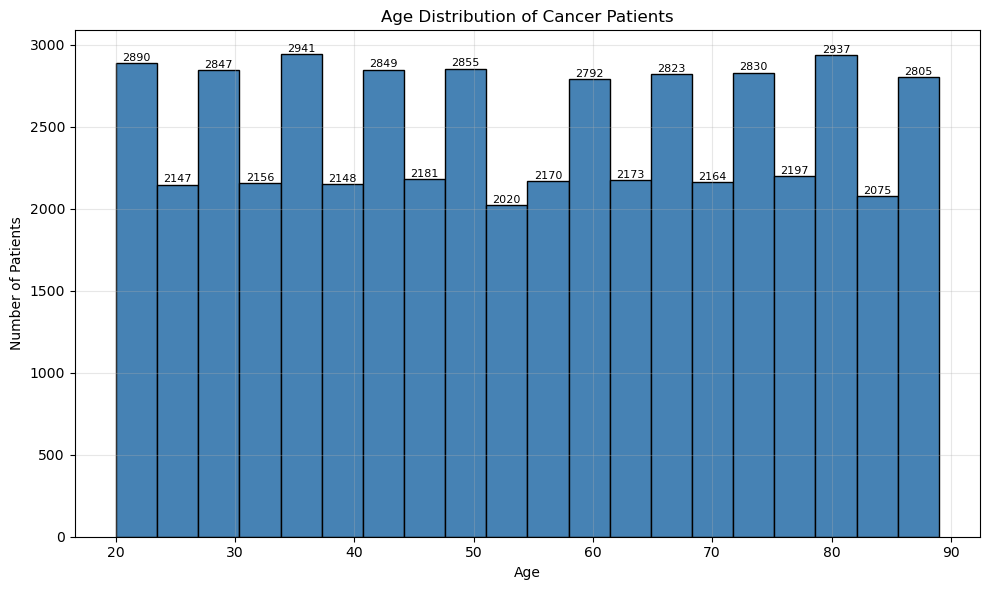


Plot 2: Mean Survival Years by Cancer Type


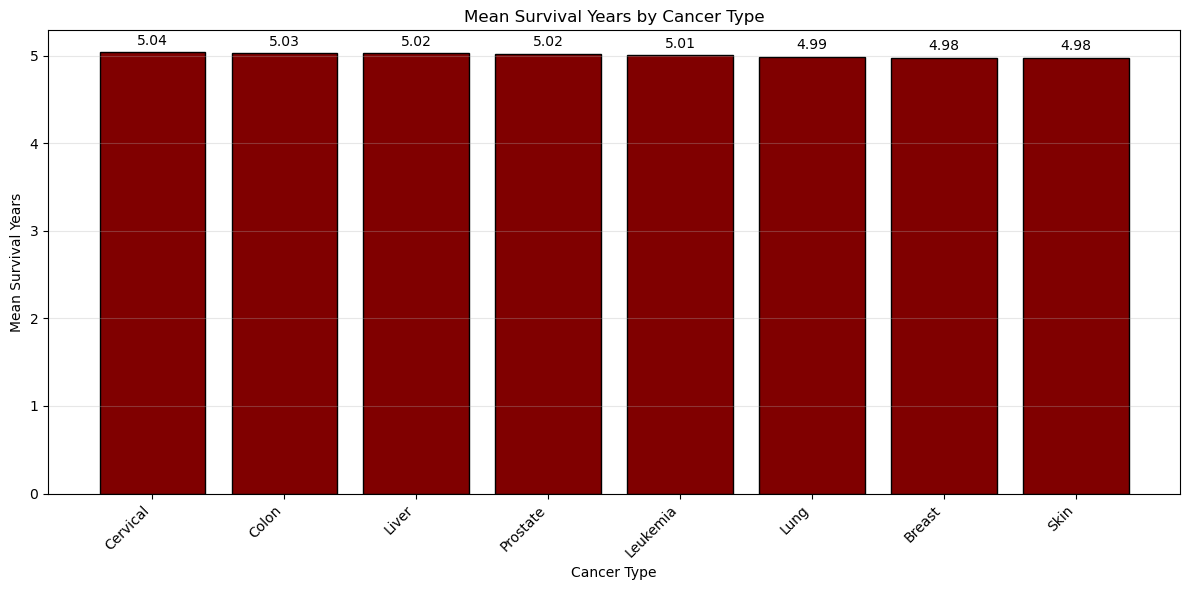


Plot 3: Mean Survival Years by Cancer Stage


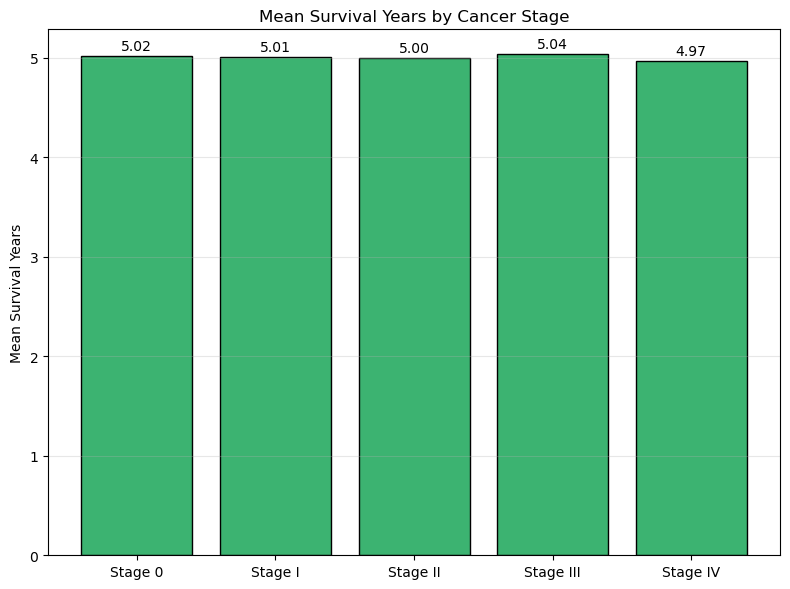


Plot 4: Cancer Cases Per Year


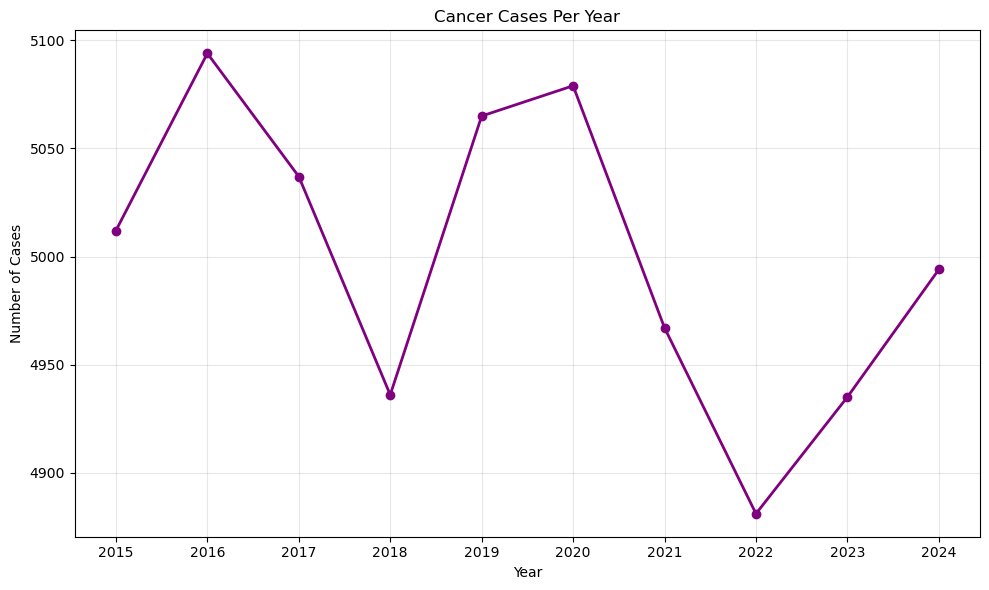


Plot 5: Top 10 Countries by Number of Cases


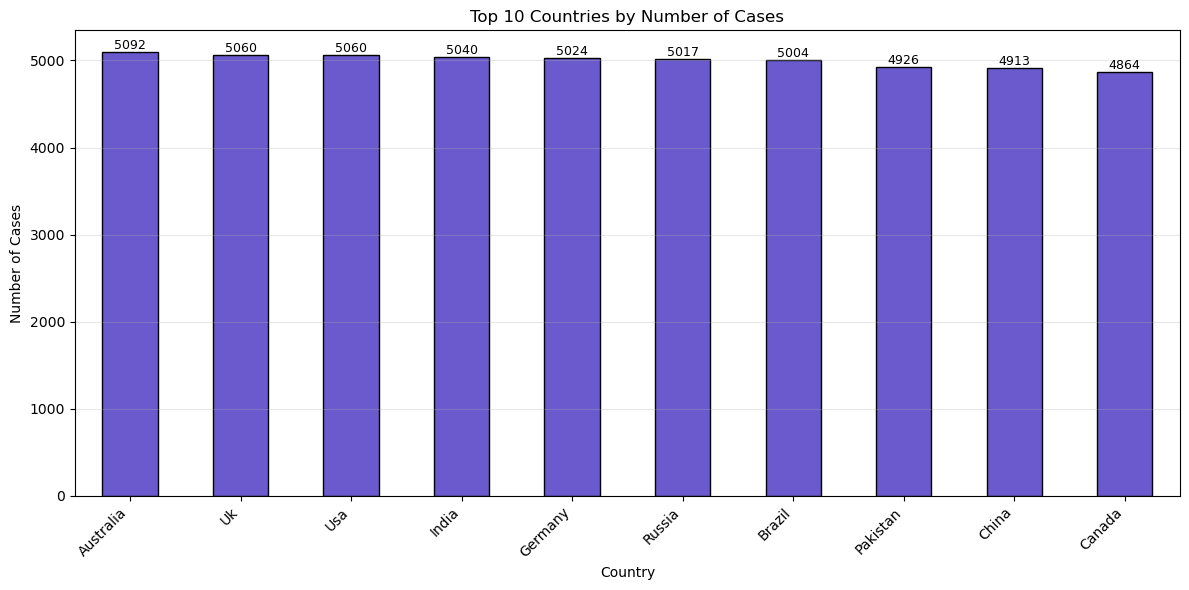


Plot 6: Treatment Cost vs Survival Years (Density Heatmap)


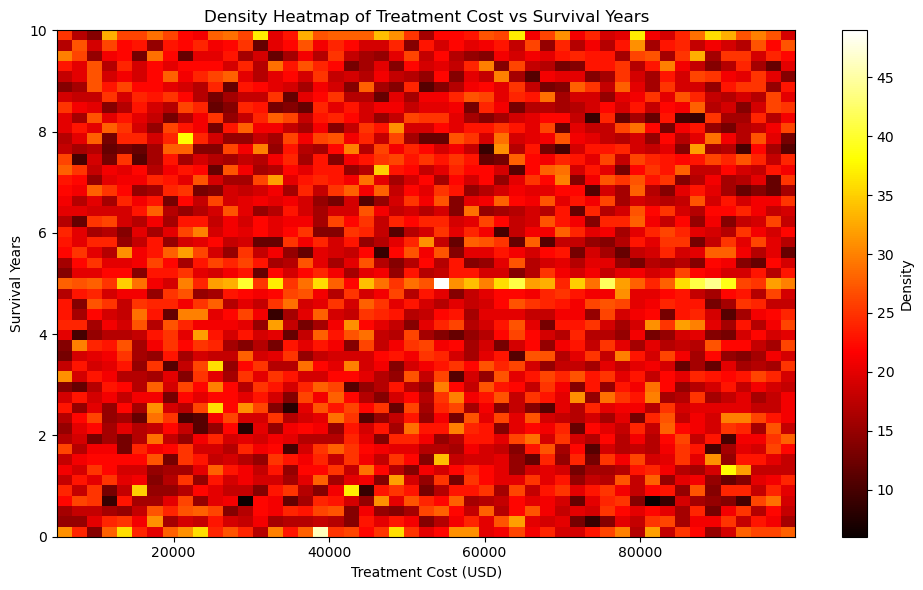


Plot 7: Gender Distribution


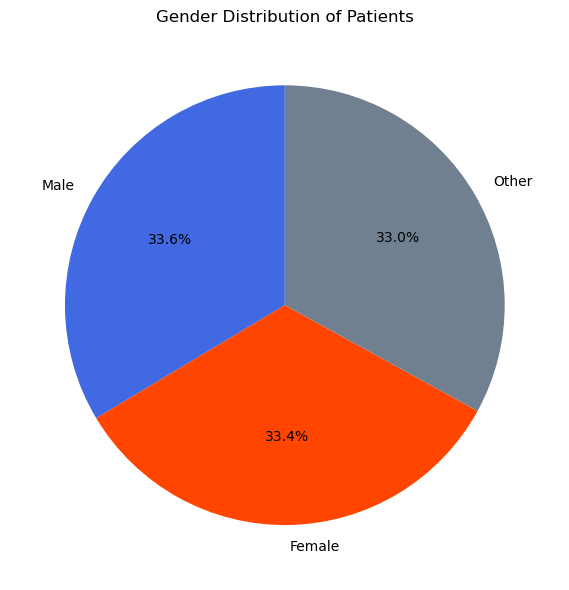


Plot 8: Genetic Risk vs Target Severity Score (with Trend Line)


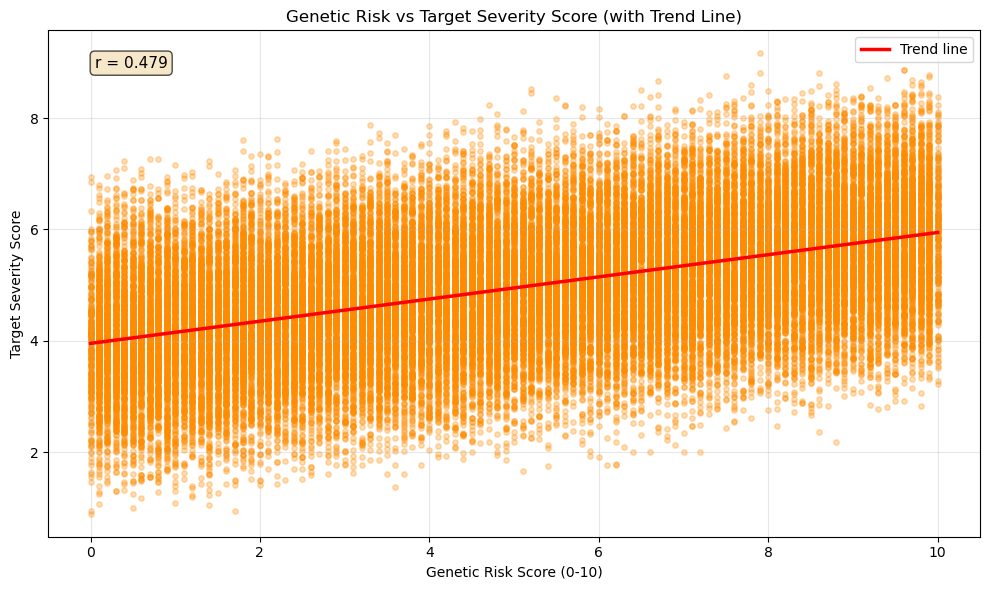

In [56]:
vis = Visualizer(df_enriched)

print("GENERATING 8 PLOTS!!")

print("\nPlot 1: Age Distribution")
vis.plot_age_distribution()

print("\nPlot 2: Mean Survival Years by Cancer Type")
vis.plot_survival_by_cancer_type(survival_by_type)

print("\nPlot 3: Mean Survival Years by Cancer Stage")
vis.plot_survival_by_stage(survival_by_stage)

print("\nPlot 4: Cancer Cases Per Year")
vis.plot_cases_per_year(cases_per_year)

print("\nPlot 5: Top 10 Countries by Number of Cases")
vis.plot_top_countries(top_countries)

print("\nPlot 6: Treatment Cost vs Survival Years (Density Heatmap)")
vis.plot_cost_vs_survival()

print("\nPlot 7: Gender Distribution")
vis.plot_gender_distribution(gender_dist)

print("\nPlot 8: Genetic Risk vs Target Severity Score (with Trend Line)")
vis.plot_genetic_risk_vs_severity()

## 4. Results and conclusions

---

### Key findings

**Age distribution (Plot 1)**  
Patient ages range from 20 to 89, concentrated in the 40–80 range, meanign cancer risk increases with age.

**Survival by cancer type (Plot 2)**  
Cervical and colon cancers show slightly higher mean survival (~5.03 years), while skin and breast are lowest (~4.98). Differences are small, meaning cancer type alone is not the dominant survival factor.

**Survival by cancer stage (Plot 3)**  
Earlier stages show better survival outcomes, with Stage IV the lowest. This confirms that early detection is critical to improving patient survival.

**Cases per year (Plot 4)**  
Case counts are consistent across 2015–2024 (~4,900–5,100 per year), showing balanced dataset coverage with no bias toward any particular year.

**Top countries (Plot 5)**  
Ten countries are represented with roughly equal distribution. Australia, UK, and USA have slightly more records (~5,060 each); Canada has the fewest (~4,864).

**Cost vs survival heatmap (Plot 6)**  
The near-zero Pearson r between treatment cost and survival suggests cost varies by healthcare system rather than clinical need in this dataset.

**Gender distribution (Plot 7)**  
Roughly equal split across Male, Female, and Other (~33% each), allowing fair cross-gender comparison.

**Genetic Risk vs Severity Score (Plot 8)**  
The strongest finding in the dataset. The red trend line shows a clear positive relationship (r ≈ 0.48) — patients with higher genetic predisposition consistently have more severe cases, making genetic screening the most actionable clinical insight from this analysis.

---

### What the analysis reveals

1. **Genetic predisposition is the strongest risk predictor** — r = 0.48 with severity, far above any environmental or lifestyle factor
2. **Cancer stage is the strongest survival predictor** — earlier detection leads to meaningfully better outcomes
3. **Treatment cost is independent of outcomes** — cost reflects regional healthcare systems, not patient need
4. **Cancer type has a subtle effect** — it influences survival and severity, but less decisively than stage or genetics

---

### Conclusion

This OOP pipeline successfully loads, cleans, analyzes, and visualizes 50,000 cancer patient records. The most insightful takeaway is that **genetic risk and cancer stage** are the two strongest predictors of patient outcomes.
